## Gradient Boosting Model

## Gradient Boosting

In [24]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance


# Search current working directory and Downloads folder for the data folder
locations = [Path.cwd(), Path.home() / "Downloads" / "Tumor_Surface_Checkpoint1_Outputs", Path.home() / "Downloads"]
data_folder = next((p for p in locations if all((p / f"checkpoint1_{s}.csv").exists() for s in ("train", "validation"))), None)

In [25]:
# Load the training and validation data, and set up the feature and target columns
train = pd.read_csv(data_folder / "checkpoint1_train.csv").set_index("sample")
val = pd.read_csv(data_folder / "checkpoint1_validation.csv").set_index("sample")
feature_cols = ["mean_expression", "enrichment", "expression_variability", "amplification_frequency"]
target_col = "dependency_score"

# Set up the training and validation data, and create a surface mask for the validation set
X_train, y_train = train[feature_cols], train[target_col]
X_val, y_val = val[feature_cols], val[target_col]
surface_mask = val["is_surface"].to_numpy(dtype=bool)

print("Train:", len(train), "(surface:", int(train.is_surface.sum()), ")")
print("Validation:", len(val), "(surface:", int(surface_mask.sum()), ")")
print("No test set accessed.")

Train: 1400 (surface: 175 )
Validation: 300 (surface: 38 )
No test set accessed.


In [26]:
# Define the hyperparameter configurations to be tested for the Gradient Boosting Regressor
configs = [
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 2, "min_samples_leaf": 5},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 2, "min_samples_leaf": 5},
    {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 2, "min_samples_leaf": 5},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 3, "min_samples_leaf": 5},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3, "min_samples_leaf": 5},
    {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 3, "min_samples_leaf": 10},
    {"n_estimators": 150, "learning_rate": 0.10, "max_depth": 2, "min_samples_leaf": 10},
]

# Build the model using a median imputer and a Gradient Boosting Regressor with the specified hyperparameters
def build_model(config, features=feature_cols):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("gb", GradientBoostingRegressor(loss="squared_error", random_state=42, **config))
    ])

# Score the model's predictions using MAE, RMSE, R2, and Spearman correlation
def score(y, pred):
    y = np.asarray(y); pred = np.asarray(pred)

    # Calculate Spearman correlation only if there are at least 3 samples\
    spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan

    return {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),  "R2": r2_score(y, pred), "Spearman": spearman_rho}

rows = []
models = {}

# For each hyperparameter configuration, build the model, fit it to the training data, 
# and evaluate it on the validation data. Store the results in a DataFrame for comparison
for i, config in enumerate(configs):
    model = build_model(config)
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    rows.append({"config_id": i, **config, "validation_MAE": mean_absolute_error(y_val, pred),
                 "surface_MAE": mean_absolute_error(y_val.to_numpy()[surface_mask], pred[surface_mask])})
    models[i] = model

tuning = pd.DataFrame(rows).sort_values(["validation_MAE", "config_id"])
display(tuning)

# Select the best model based on the lowest validation MAE and evaluate it
best_id = int(tuning.iloc[0]["config_id"])
best_config = configs[best_id]
best_model = models[best_id]
val_predictions = best_model.predict(X_val)


print("Selected configuration:", best_id, best_config)

,config_id,n_estimators,learning_rate,max_depth,min_samples_leaf,validation_MAE,surface_MAE
1,1,200,0.05,2,5,0.206664,0.183577
0,0,100,0.05,2,5,0.206951,0.181472
2,2,300,0.03,2,5,0.207008,0.182387
3,3,100,0.05,3,5,0.207927,0.191801
6,6,150,0.10,2,10,0.208054,0.178125
5,5,300,0.03,3,10,0.208137,0.187282
4,4,200,0.05,3,5,0.210099,0.203939


Selected configuration: 1 {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 5}


In [27]:
# Evaluate the best model and a constant baseline model on the validation set
constant = DummyRegressor(strategy="mean").fit(X_train, y_train)
constant_pred = constant.predict(X_val)
metric_rows = []

# Evaluate both the constant baseline model and the best Gradient Boosting model
for model_name, pred in [("Constant", constant_pred), ("Gradient boosting", val_predictions)]:
    for subset, mask in [("Overall", np.ones(len(val), dtype=bool)), ("Surface", surface_mask)]:
        metric_rows.append({"Model": model_name, "Subset": subset, "N": int(mask.sum()),
                            **score(y_val.to_numpy()[mask], pred[mask])})

metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))

/var/folders/zg/747my4dd0dd82wrv7jq9djjm0000gn/T/ipykernel_61215/993249257.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan
/var/folders/zg/747my4dd0dd82wrv7jq9djjm0000gn/T/ipykernel_61215/993249257.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan


,Model,Subset,N,MAE,RMSE,R2,Spearman
0,Constant,Overall,300,0.2355,0.3874,-0.0037,NaN
1,Constant,Surface,38,0.1970,0.2372,-0.1790,NaN
2,Gradient boosting,Overall,300,0.2067,0.3651,0.1085,0.4121
3,Gradient boosting,Surface,38,0.1836,0.2973,-0.8525,0.4605


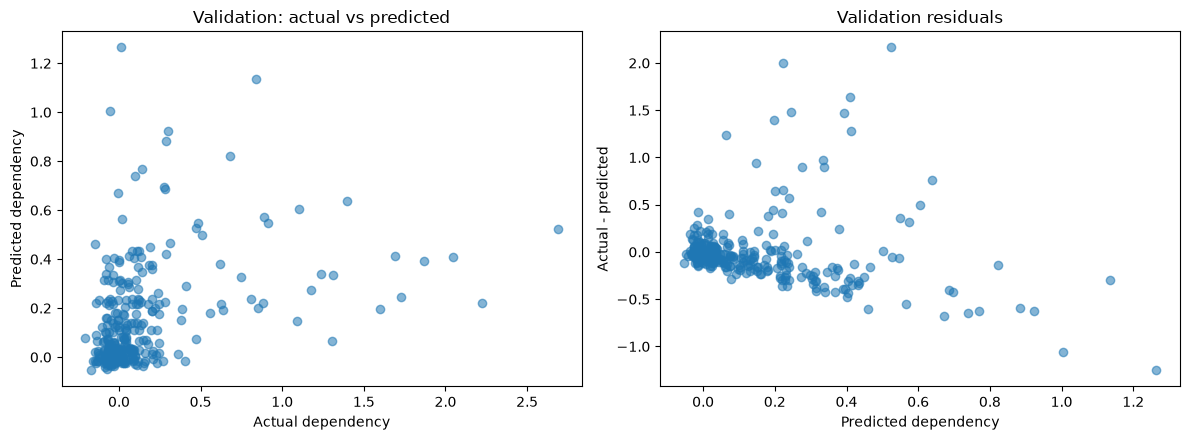

,feature,tree_importance
2,expression_variability,0.368917
0,mean_expression,0.351835
1,enrichment,0.244649
3,amplification_frequency,0.034599


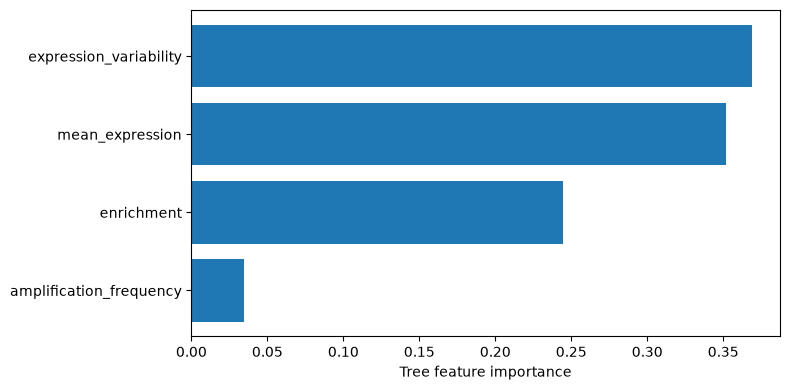

,feature,MAE_increase_mean,MAE_increase_sd
2,expression_variability,0.03048,0.00576
1,enrichment,0.02259,0.00464
0,mean_expression,0.01600,0.00525
3,amplification_frequency,0.00236,0.00116


In [28]:
# Plot the actual vs predicted dependency scores and the residuals for the best model on the validation set
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_val, val_predictions, alpha=0.55)
axes[0].set(xlabel="Actual dependency", ylabel="Predicted dependency", title="Validation: actual vs predicted")
residuals = y_val.to_numpy() - val_predictions

axes[1].scatter(val_predictions, residuals, alpha=0.55)
axes[1].set(xlabel="Predicted dependency", ylabel="Actual - predicted", title="Validation residuals")

plt.tight_layout(); plt.show()

importance = pd.DataFrame({"feature": feature_cols, "tree_importance": best_model.named_steps["gb"].feature_importances_}).sort_values("tree_importance", ascending=False)
display(importance)

plt.figure(figsize=(8, 4)); plt.barh(importance.feature[::-1], importance.tree_importance[::-1]); plt.xlabel("Tree feature importance"); plt.tight_layout(); plt.show()

permutation = permutation_importance(best_model, X_val, y_val, n_repeats=20, random_state=42,
                              scoring="neg_mean_absolute_error")

perm_df = pd.DataFrame({"feature": feature_cols, "MAE_increase_mean": permutation.importances_mean,
                        "MAE_increase_sd": permutation.importances_std}).sort_values("MAE_increase_mean", ascending=False)

display(perm_df.round(5))

,predicted_dependency,dependency_score,absolute_error,amplification_frequency,mean_expression
sample,,,,,
ZDHHC5,1.264446,0.011439,1.253007,0.005814,11.444761
EPN1,0.670666,-0.004669,0.675335,0.007752,11.310908
SLC3A2,0.525756,0.473682,0.052073,0.003876,11.681265
SNAP23,0.500577,0.505550,0.004973,0.000000,10.504822
LRRC45,0.449770,0.189501,0.260269,0.034884,8.814010
MARCKSL1,0.375205,0.186268,0.188936,0.007752,11.696356
ERBB3,0.346505,0.138888,0.207617,0.023256,12.019299
PFDN1,0.328500,0.746865,0.418364,0.003876,10.187203
APPL1,0.311103,-0.000687,0.311790,0.001938,10.083684


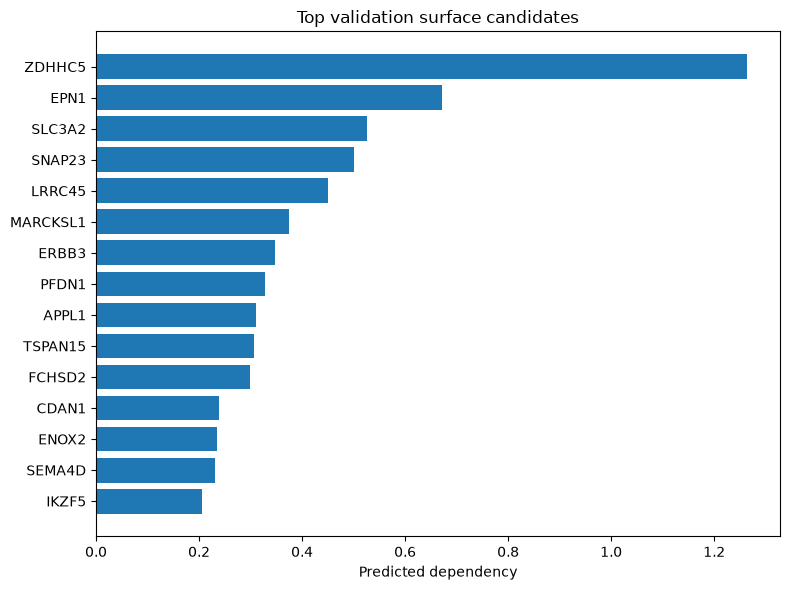

In [29]:
# Rank the validation samples by predicted dependency score, and display the top surface candidates
ranking = val.copy()
ranking["predicted_dependency"] = val_predictions
ranking["absolute_error"] = np.abs(y_val.to_numpy() - val_predictions)
surface_ranking = ranking.loc[ranking.is_surface].sort_values("predicted_dependency", ascending=False)

display(surface_ranking[["predicted_dependency", "dependency_score", "absolute_error", "amplification_frequency", "mean_expression"]].head(20))
top = surface_ranking.head(15).iloc[::-1]

plt.figure(figsize=(8, 6)); plt.barh(top.index, top.predicted_dependency)
plt.xlabel("Predicted dependency"); plt.title("Top validation surface candidates"); plt.tight_layout(); plt.show()

In [30]:
ablation_rows = []

# Evaluate the model performance with all features and without the amplification frequency feature
for feature_group, cols in [("All four", feature_cols),
                          ("No amplification", [c for c in feature_cols if c != "amplification_frequency"])]:
    for i, config in enumerate(configs):
        trained_model = build_model(config, cols).fit(train[cols], y_train)
        model_pred = trained_model.predict(val[cols])
        ablation_rows.append({"Feature set": feature_group, "config_id": i,
                             "MAE": mean_absolute_error(y_val, model_pred),
                             "Surface MAE": mean_absolute_error(y_val.to_numpy()[surface_mask], model_pred[surface_mask]),
                             "Spearman": score(y_val, model_pred)["Spearman"]})

ablation_all = pd.DataFrame(ablation_rows)
ablation_best = ablation_all.sort_values(["MAE", "config_id"]).groupby("Feature set", as_index=False).first()
display(ablation_best.round(5))

,Feature set,config_id,MAE,Surface MAE,Spearman
0,All four,1,0.20666,0.18358,0.41210
1,No amplification,0,0.20781,0.18274,0.40716


In [31]:
random_generator = np.random.default_rng(42)
bootstrap_rows = []

# For each subset (Overall and Surface), perform bootstrap resampling to estimate the confidence intervals for MAE and Spearman correlation
for subset, mask in [("Overall", np.ones(len(val), dtype=bool)), ("Surface", surface_mask)]:
    yt = y_val.to_numpy()[mask]; yp = val_predictions[mask]
    # Perform 1000 bootstrap resamples to calculate MAE and Spearman correlation for each resample
    for _ in range(1000):
        idx = random_generator.integers(0, len(yt), len(yt))
        bootstrap_rows.append({"Subset": subset, "MAE": mean_absolute_error(yt[idx], yp[idx]),
            "Spearman": score(yt[idx], yp[idx])["Spearman"]})

# Calculate the 2.5% and 97.5% quantiles for MAE and Spearman correlation for each subset to estimate the confidence intervals
boot = pd.DataFrame(bootstrap_rows)
confidence_intervals_rows = []
for subset, subset_group in boot.groupby("Subset"):
    for metric in ["MAE", "Spearman"]:
        confidence_intervals_rows.append({"Subset": subset, "Metric": metric,
                        "2.5%": subset_group[metric].quantile(.025), "97.5%": subset_group[metric].quantile(.975)})

display(pd.DataFrame(confidence_intervals_rows).round(4))

,Subset,Metric,2.5%,97.5%
0,Overall,MAE,0.1732,0.2447
1,Overall,Spearman,0.3071,0.5150
2,Surface,MAE,0.1182,0.2633
3,Surface,Spearman,0.1954,0.6774
